# Sparse Audio Source Separation: Three Sources, Two Mixtures

**Question:** how can three unknown source signals be recovered from only two observed channels?

This study combines the [STFT](01_time_frequency_analysis.ipynb) with the sparse-representation idea explored in [wavelet denoising](02_wavelet_image_denoising.ipynb). It is an implementation study grounded in Bofill & Zibulevsky (2001) and Cano et al. (2019), **not a reproduction of their published benchmark results**.

The experiment uses the original bird, female-voice and male-voice recordings from the third lab. The files are included in `data/audio/separation/`; the original trimming and common 15 kHz playback convention are preserved.

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Markdown, Image, Audio

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/signal_inverse").is_dir():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
from signal_inverse.datasets import load_inputs
from signal_inverse.experiments import run_separation

inputs = load_inputs(ROOT / "data")
output = ROOT / "results" / "separation"

def figure(name):
    display(Image(filename=str(output / (name + ".png")), width=1000))

def table(rows, columns):
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for row in rows:
        values = [f"{row[c]:.3f}" if isinstance(row[c], (float, np.floating)) else str(row[c]) for c in columns]
        lines.append("| " + " | ".join(values) + " |")
    display(Markdown("\n".join(lines)))

print("Inputs: original course image and recordings bundled in data/.")

Inputs: original course image and recordings bundled in data/.


## 1. The observation model

We synthesize instantaneous, noiseless linear mixtures:

$$X=AS,\quad A_{:,j}=(\cos\phi_j,\sin\phi_j)^T,\quad \phi=(30^\circ,90^\circ,150^\circ).$$

Each column has unit norm. These are abstract mixing directions, modulo 180 degrees, not estimated physical arrival angles. In particular the 150-degree column includes a negative coefficient; this is broader than ordinary nonnegative stereo panning. There are no delays, reverberation or moving sources.

Three unknowns per sample and two equations make the system underdetermined. Recovery needs extra structure: many time-frequency bins should be dominated by one source.

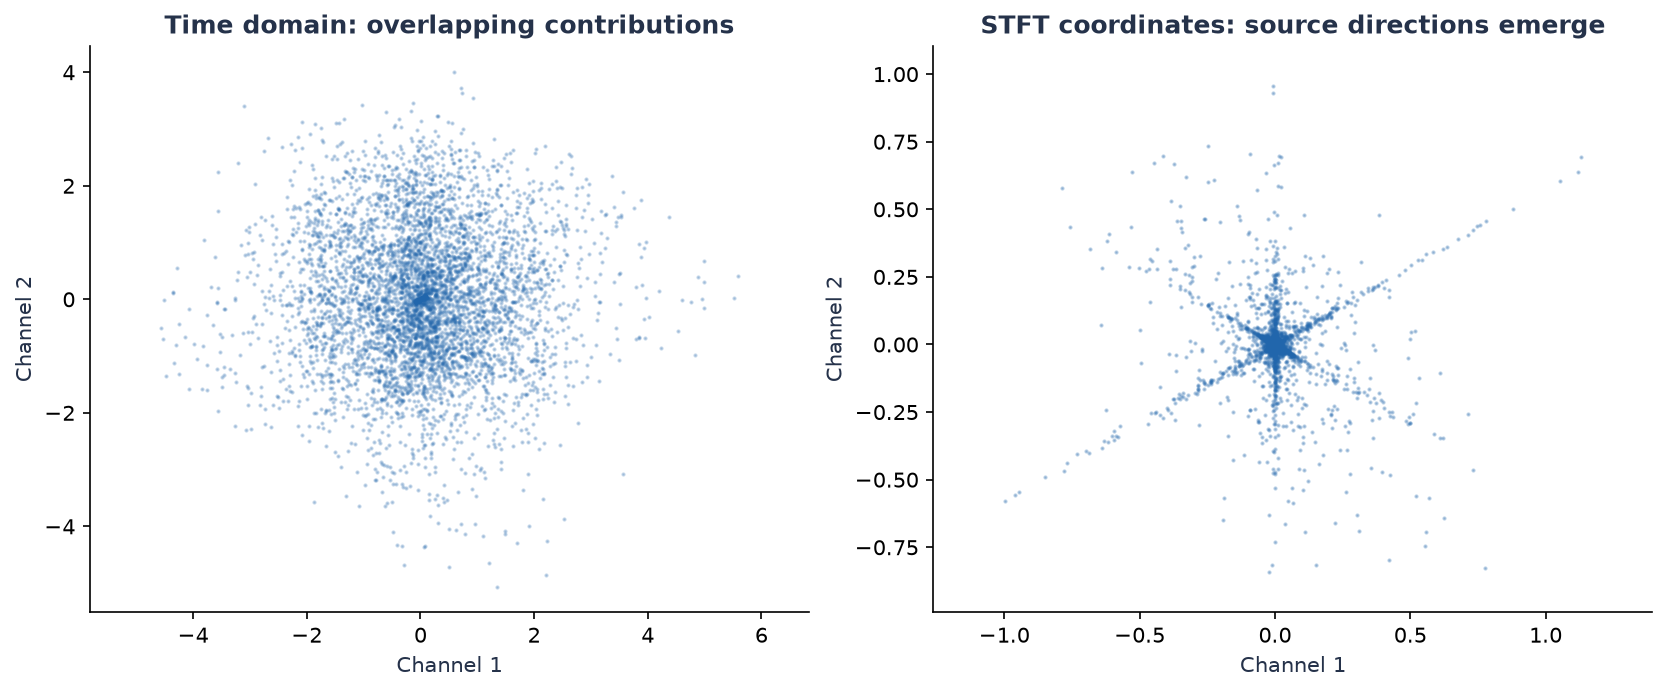

In [2]:
report = run_separation(inputs, output)
figure("sparse_geometry")

## 2. Where the articles enter the implementation

| Source | Role here | Scope of the implementation |
| --- | --- | --- |
| Bofill & Zibulevsky (2001), Sections 4-6 | Sparse representations, two-dimensional minimum-L1 reconstruction, real/imaginary transform coordinates | Enumerate two-column bases for each real coordinate; use matched STFT analysis/synthesis |
| Cano et al. (2019), “Musical source position models” | Spatial mixture geometry, source-dominated TF bins and masking | Estimate mixing directions and compare binary assignment with sparse reconstruction |

The histogram estimator is inherited from the course implementation. It takes one peak in each third of $[0,\pi)$, so the **number of sources and their broad angular sectors are assumed known**. It is not the paper's potential-function clustering algorithm.

Bins with energy below 10% of the maximum are excluded from direction estimation. Real and imaginary coordinate vectors of the retained complex bins enter a 35-bin angular histogram on a fixed range.

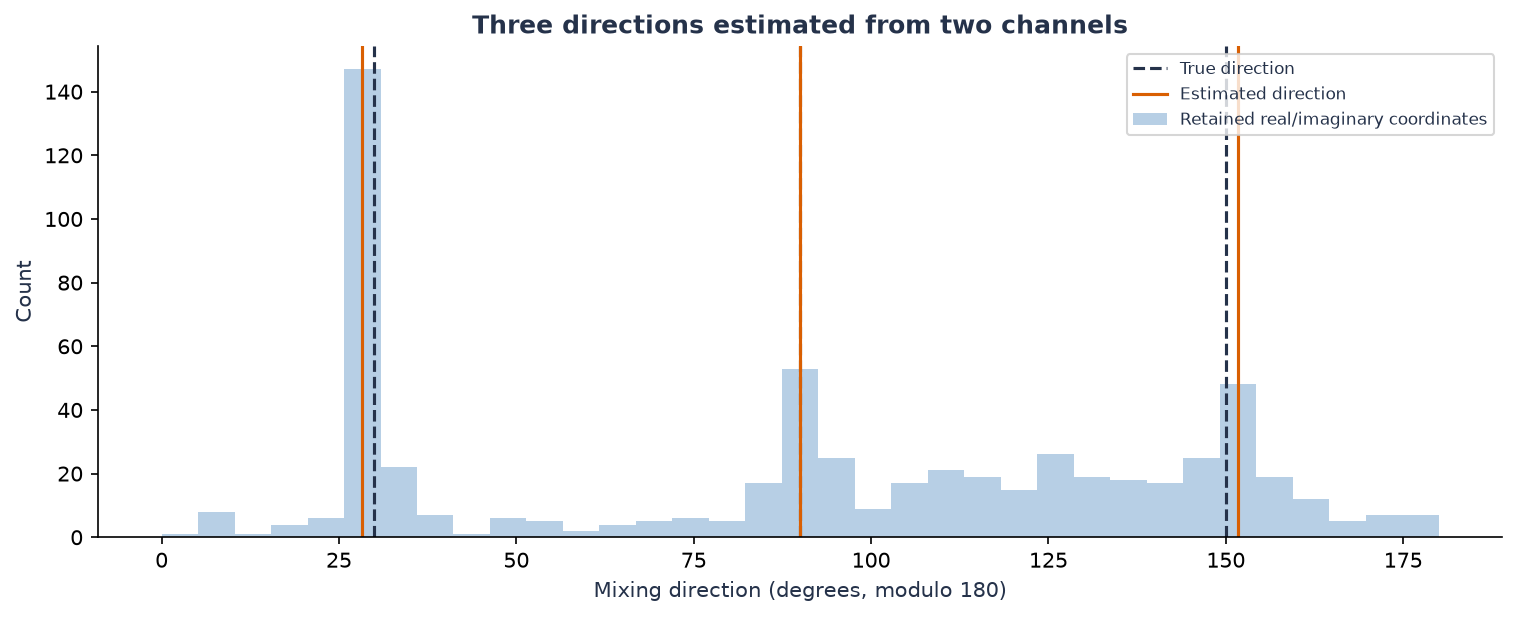

| source | true_degrees | estimated_degrees | absolute_error_degrees |
| --- | --- | --- | --- |
| Bird | 30.000 | 28.286 | 1.714 |
| Female voice | 90.000 | 90.000 | 0.000 |
| Male voice | 150.000 | 151.714 | 1.714 |

| energy_ratio | mean_angle_error_degrees |
| --- | --- |
| 0.000 | 1.143 |
| 0.080 | 1.143 |
| 0.100 | 1.143 |
| 0.150 | 1.143 |
| 0.200 | 1.143 |

In [3]:
figure("estimated_directions")
table(report["directions"], ["source", "true_degrees", "estimated_degrees", "absolute_error_degrees"])
table(report["direction_sensitivity"], ["energy_ratio", "mean_angle_error_degrees"])

## 3. Two reconstruction strategies

**Binary masking.** Project each complex observation onto the estimated unit directions and assign it to the largest-magnitude projection. Only the assigned source keeps that coefficient. This is the baseline from the supplied implementation.

**Split real/imaginary L1.** For a real observation $x\in\mathbb R^2$, solve

$$\min_{s\in\mathbb R^3}\|s\|_1\quad\text{subject to}\quad \hat A s=x.$$

A full-row-rank real linear program admits an optimum with at most two nonzero entries. Enumerating nonsingular two-column bases and choosing the smallest objective gives the optimum. We solve separately for real and imaginary coordinates, then recombine them. Thus the complex-coordinate objective is

$$\sum_j\bigl(|\operatorname{Re}s_j|+|\operatorname{Im}s_j|\bigr),$$

which differs from $\sum_j|s_j|$ with complex magnitudes. Primal-dual optimality certificates verify the real solver independently of its basis-selection criterion. Both strategies discard the bottom 50% of mixture-energy bins, following the original heuristic; the constraint is not preserved in discarded bins.

**Correction from the original bonus:** a pair chosen using only the real part is no longer applied indiscriminately to the imaginary part. Signed directions and angular wrap-around are handled by basis enumeration. This corrects the implementation without claiming a new separation algorithm.

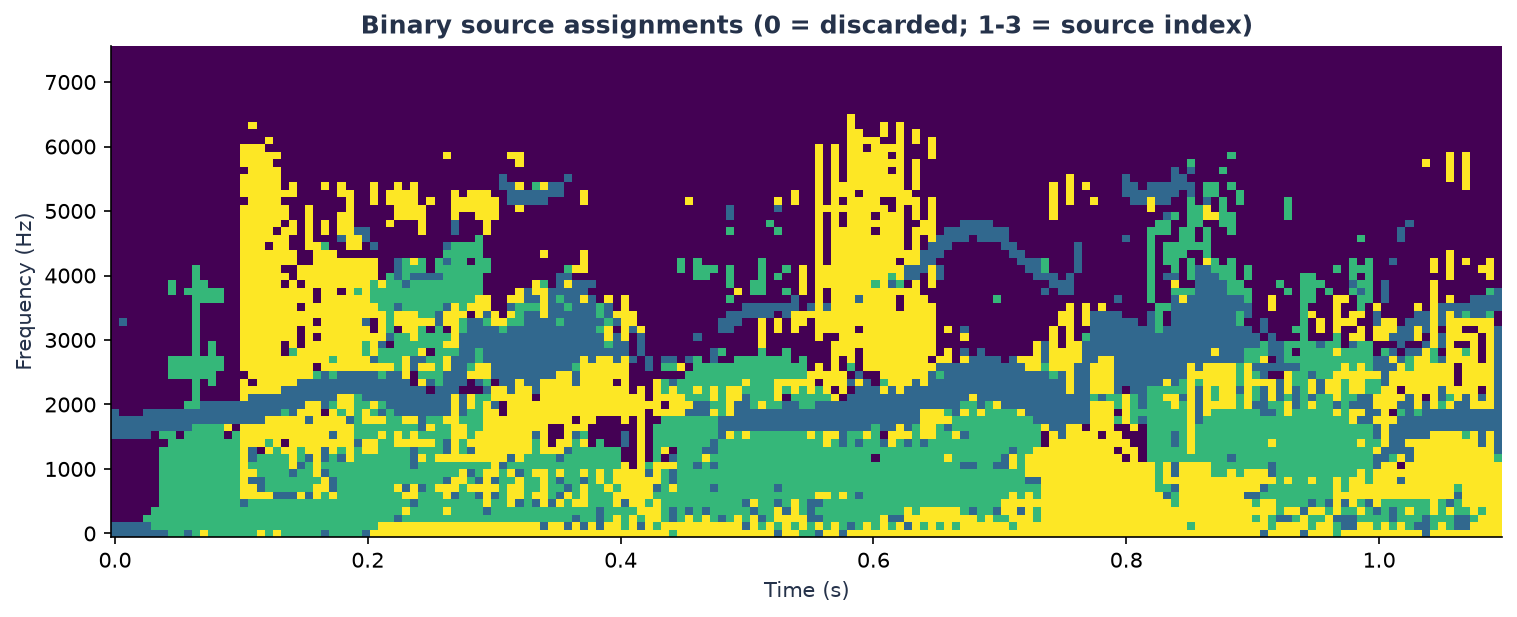

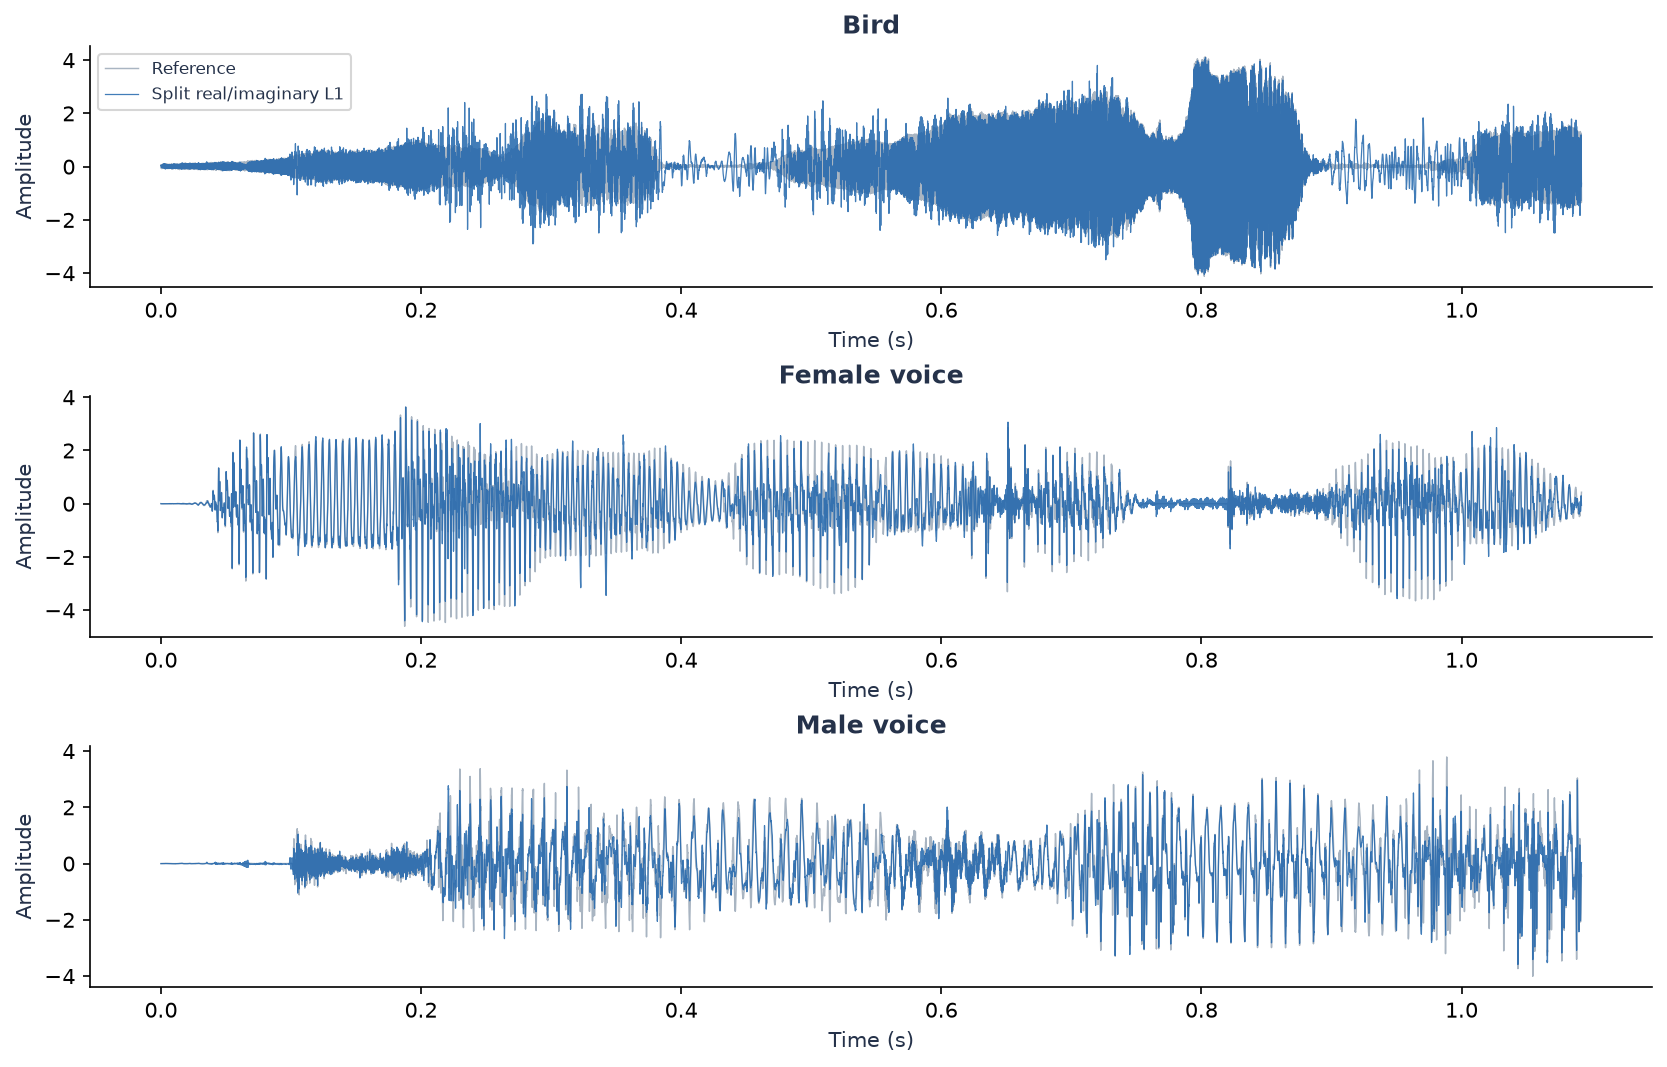

In [4]:
figure("binary_assignments")
figure("reconstructed_sources")

## 4. Evaluate without hiding the baseline

SI-SDR removes a global scale mismatch and compares the target projection with its residual (Le Roux et al., 2019). Reference sources are used **only for evaluation and permutation matching**, never for estimating directions or reconstructing sources.

Each reconstructed source is compared with the best of the two unprocessed input channels. The baseline is intentionally generous and reference-aware. Reported improvement is SI-SDR relative to that best-channel baseline; it is not a perceptual quality score.

| method | source | si_sdr_db | best_mixture_si_sdr_db | improvement_db |
| --- | --- | --- | --- | --- |
| binary | Bird | 8.566 | -0.020 | 8.586 |
| binary | Female voice | 3.020 | 2.994 | 0.026 |
| binary | Male voice | 2.989 | -0.020 | 3.010 |
| split_l1 | Bird | 7.921 | -0.020 | 7.942 |
| split_l1 | Female voice | 7.415 | 2.994 | 4.422 |
| split_l1 | Male voice | 7.214 | -0.020 | 7.234 |

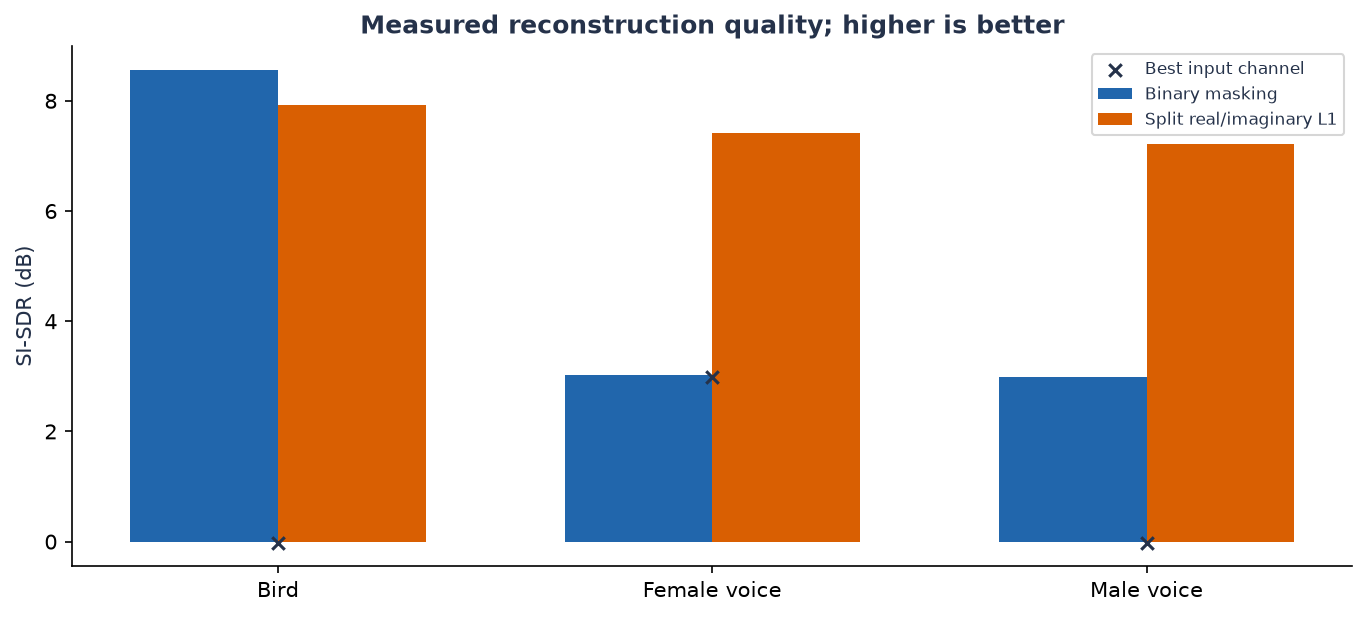

In [5]:
table(report["scores"], ["method", "source", "si_sdr_db", "best_mixture_si_sdr_db", "improvement_db"])
figure("separation_scores")

## 5. Listen to the result

Listen to the mixture, then one reference and its two reconstructions. WAVs are peak-normalized independently for comfortable playback. The numerical evaluation uses unnormalized arrays, so loudness differences in these previews are not metric evidence. All three sources have exported reference and reconstructed tracks in the results directory.

In [6]:
for filename, label in [("mixture_stereo.wav", "Stereo mixture"),
                        ("reference_source_1.wav", "Reference: source 1"),
                        ("binary_source_1.wav", "Binary masking: source 1"),
                        ("split_l1_source_1.wav", "Split real/imaginary L1: source 1")]:
    display(Markdown(f"**{label}**"))
    display(Audio(filename=str(output / filename)))

**Stereo mixture**

**Reference: source 1**

**Binary masking: source 1**

**Split real/imaginary L1: source 1**

## Findings and limits

The STFT changes the geometry of the mixtures, making source directions visible. Sparse reconstruction permits two nonzero source contributions per real TF coordinate, whereas binary masking assigns one source per complex bin. This difference does not guarantee that L1 wins for every source.

The assumptions are restrictive: three sector-separated directions, fixed mixing, three recorded excerpts and no sensor noise. Simultaneous source overlap, similar spectra, reverberation and inaccurate mixing directions can all undermine recovery. Resolving permutation and global scale is necessary for evaluation, but does not repair artifacts.

**Connection:** [optimization for image restoration](04_optimization_image_restoration.ipynb) generalizes the pattern “observation model + prior + reconstruction procedure” to noisy and incomplete images.

**Read further:** [method-to-paper mapping](../docs/source-separation.md), [bibliography and DOI links](../REFERENCES.md), and [provenance](../docs/provenance.md).